# UCU Data Mining and Wrangling - Group 2

## Jumia Nigeria preliminary analysis using accepted Daily Runs 1-5

**Categories:** Phones & Tablets, Computing and Electronics  
**Observation dates:** 13-17 October 2026 (`Africa/Nairobi`)  
**Scope:** Preliminary analysis of 5 of 7 planned collection dates; the seven-day collection is not yet complete.

## B. Objectives

The final notebook will compare category price distributions, identify price outliers, investigate price and rating, and examine whether review counts can act as a cautious popularity indicator. It will also track seven-day price and discount changes, identify products with the largest movements, find dominant brands, and evaluate whether displayed discounts agree with calculated discounts.

The original Group 2 research question is: **Which brands provide the best balance of lower prices, strong ratings and high review counts?** Accepted Daily Runs 1-5 support preliminary comparisons, but final time-based conclusions require all seven genuine daily files.

## C. Setup

Imports, display settings, robust project paths and reproducibility information are defined below.

In [1]:
from pathlib import Path
import platform
import sqlite3
from contextlib import closing

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

EXPECTED_CATEGORIES = {"Phones & Tablets", "Computing", "Electronics"}

In [2]:
def find_project_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().resolve()]
    for candidate in candidates:
        database = candidate / "database" / "jumia_ng.sqlite"
        if database.exists():
            return candidate.resolve()
    raise FileNotFoundError("Run this notebook from the repository root or notebooks folder.")


PROJECT_ROOT = find_project_root()
DATABASE_PATH = PROJECT_ROOT / "database" / "jumia_ng.sqlite"

# Open SQLite in read-only mode and load all accepted observation dates.
database_uri = f"file:{DATABASE_PATH.as_posix()}?mode=ro"
with closing(sqlite3.connect(database_uri, uri=True)) as connection:
    database_counts = {
        table: connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
        for table in ("products", "categories", "product_categories", "observations")
    }
    df = pd.read_sql_query(
        '''
        SELECT
            p.source_product_id,
            p.product_name,
            p.brand,
            o.current_price,
            o.old_price,
            o.displayed_discount_percentage,
            o.calculated_discount_percentage,
            o.rating,
            o.review_count,
            (
                SELECT GROUP_CONCAT(c.category_name, ' | ')
                FROM product_categories AS pc
                JOIN categories AS c ON c.category_id = pc.category_id
                WHERE pc.product_id = p.product_id
            ) AS category,
            p.product_url,
            o.currency,
            p.source_site,
            o.scraped_at,
            o.scrape_date
        FROM observations AS o
        JOIN products AS p ON p.product_id = o.product_id
        ORDER BY o.scrape_date, o.scraped_at, p.source_product_id
        ''',
        connection,
    )

available_dates = sorted(df["scrape_date"].unique())
run_label = f"{len(available_dates)} Accepted Dates"

print(f"Project root: {PROJECT_ROOT}")
print(f"Read-only database: {DATABASE_PATH.relative_to(PROJECT_ROOT)}")
print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}; matplotlib: {matplotlib.__version__}; seaborn: {sns.__version__}")
print(f"Database counts: {database_counts}")
print(f"Observation dates loaded: {available_dates}")

Project root: C:\Users\ALEX\Desktop\YEAR 2 SEM 1\MINERS\MAIN-JUMIA\DSC2107_Group2_Jumia_Main
Read-only database: database\jumia_ng.sqlite
Python: 3.13.9
pandas: 2.3.3; matplotlib: 3.11.2; seaborn: 0.13.2
Database counts: {'products': 771, 'categories': 3, 'product_categories': 771, 'observations': 3113}
Observation dates loaded: ['2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17']


## D. Data inspection

The following cells inspect structure, categories, product identity and timestamp coverage before analysis.

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nFirst five records:")
display(df.head())

Rows: 3,113
Columns: 15

Column names:
['source_product_id', 'product_name', 'brand', 'current_price', 'old_price', 'displayed_discount_percentage', 'calculated_discount_percentage', 'rating', 'review_count', 'category', 'product_url', 'currency', 'source_site', 'scraped_at', 'scrape_date']

Data types:


,dtype
source_product_id,object
product_name,object
brand,object
current_price,float64
old_price,float64
displayed_discount_percentage,float64
calculated_discount_percentage,float64
rating,float64
review_count,float64
category,object



First five records:


,source_product_id,product_name,brand,current_price,old_price,displayed_discount_percentage,calculated_discount_percentage,rating,review_count,category,product_url,currency,source_site,scraped_at,scrape_date
0,AC431EA7LKZHVNAFAMZ,Ace Elec 20000 MAh Utra Slim Portable Power Ba...,Ace Elec,"7,650.00","12,000.00",36.00,36.25,3.70,"164,071.00",Phones & Tablets,https://www.jumia.com.ng/ace-elec-20000-mah-ut...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13
1,BR644EA7WIMKINAFAMZ,SupDevice Authentic 20000mAh High-Capacity Por...,SupDevice,"8,978.00","64,800.00",86.00,86.15,3.20,252.00,Phones & Tablets,https://www.jumia.com.ng/supdevice-authentic-2...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13
2,BR897EA6V9GSANAFAMZ,Kingnote 2.19''inch C90PRO Ultra 3 Smartwatch ...,Kingnote,"5,700.00","28,800.00",80.00,80.21,3.50,"1,095.00",Phones & Tablets,https://www.jumia.com.ng/kingnote-2.19inch-c90...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13
3,BR897EA75UZCQNAFAMZ,Kingnote 2.09''inch T900U Smartwatch Native St...,Kingnote,"3,482.00","21,600.00",84.00,83.88,3.40,988.00,Phones & Tablets,https://www.jumia.com.ng/kingnote-2.09inch-t90...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13
4,EA369EA7SKV8RNAFAMZ,EASYPIE 27000MAh Power Bank Ultra Slim Portabl...,EASYPIE,"12,420.00","72,000.00",83.00,82.75,3.70,346.00,Phones & Tablets,https://www.jumia.com.ng/easypie-27000mah-powe...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13


In [4]:
category_date_counts = pd.crosstab(df["scrape_date"], df["category"])
unique_products = df["source_product_id"].nunique()
timestamps = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)

display(category_date_counts)
print(f"Unique products: {unique_products:,}")
print(f"Scrape-date coverage: {df['scrape_date'].min()} to {df['scrape_date'].max()}")
print(f"Timestamp coverage (UTC): {timestamps.min()} to {timestamps.max()}")

category,Computing,Electronics,Phones & Tablets
scrape_date,,,
2026-10-13,200,200,239
2026-10-14,200,200,200
2026-10-15,200,200,239
2026-10-16,200,200,200
2026-10-17,198,199,238


Unique products: 771
Scrape-date coverage: 2026-10-13 to 2026-10-17
Timestamp coverage (UTC): 2026-10-13 16:23:12.789328+00:00 to 2026-10-17 19:41:38.426343+00:00


## E. Data-quality checks

Missing values are reported rather than replaced with zero. Duplicate and validity checks are calculated directly from all five accepted observation dates.

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
}).sort_values(["missing_count", "missing_percentage"], ascending=False)
display(missing)

,missing_count,missing_percentage
old_price,146,4.69
displayed_discount_percentage,146,4.69
calculated_discount_percentage,146,4.69
rating,19,0.61
review_count,19,0.61
source_product_id,0,0.00
product_name,0,0.00
brand,0,0.00
current_price,0,0.00
category,0,0.00


In [6]:
parsed_timestamps = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)
nairobi_dates = parsed_timestamps.dt.tz_convert("Africa/Nairobi").dt.date.astype("string")

quality_checks = pd.Series({
    "accepted_collection_dates": len(available_dates),
    "products_observed_on_all_available_dates": int((df.groupby("source_product_id")["scrape_date"].nunique() == len(available_dates)).sum()),
    "duplicate_product_date_rows": int(df.duplicated(["source_product_id", "scrape_date"]).sum()),
    "duplicate_observations": int(df.duplicated(["source_product_id", "scraped_at"]).sum()),
    "missing_or_invalid_timestamps": int(parsed_timestamps.isna().sum()),
    "timestamp_date_mismatches": int((nairobi_dates != df["scrape_date"].astype("string")).sum()),
    "negative_current_prices": int((df["current_price"] < 0).sum()),
    "negative_old_prices": int((df["old_price"] < 0).sum()),
    "impossible_prices_over_1bn_NGN": int(((df["current_price"] > 1_000_000_000) | (df["old_price"] > 1_000_000_000)).sum()),
    "ratings_outside_0_to_5": int(((df["rating"] < 0) | (df["rating"] > 5)).sum()),
    "unexpected_category_values": int((~df["category"].isin(EXPECTED_CATEGORIES)).sum()),
})
display(quality_checks.rename("count").to_frame())
print("Observed categories:", sorted(df["category"].unique()))
print("Category set matches expectation:", set(df["category"].unique()) == EXPECTED_CATEGORIES)

,count
accepted_collection_dates,5
products_observed_on_all_available_dates,491
duplicate_product_date_rows,0
duplicate_observations,0
missing_or_invalid_timestamps,0
timestamp_date_mismatches,0
negative_current_prices,0
negative_old_prices,0
impossible_prices_over_1bn_NGN,0
ratings_outside_0_to_5,0


Observed categories: ['Computing', 'Electronics', 'Phones & Tablets']
Category set matches expectation: True


### Data-quality interpretation

The database contains 3,113 observations for 771 unique products. Exactly 491 products appear on all five accepted dates, and there are no duplicate product-and-date rows or duplicate product-and-timestamp observations. All prices are non-negative and below the documented impossible-price threshold, all available ratings lie between 0 and 5, all timestamps parse correctly, and the three observed categories match the assignment.

Missing values are genuine: 146 observations have no old price, displayed discount or calculated discount, and 19 observations have no rating or review count. These values stay missing because zero would incorrectly claim a price, discount, rating or review count that Jumia did not display.

## F. Preliminary accepted-run analysis

These charts describe the accepted observations from 13-17 October. They cover 5 of 7 planned collection dates, so they are preliminary and do not represent the full seven-day period.

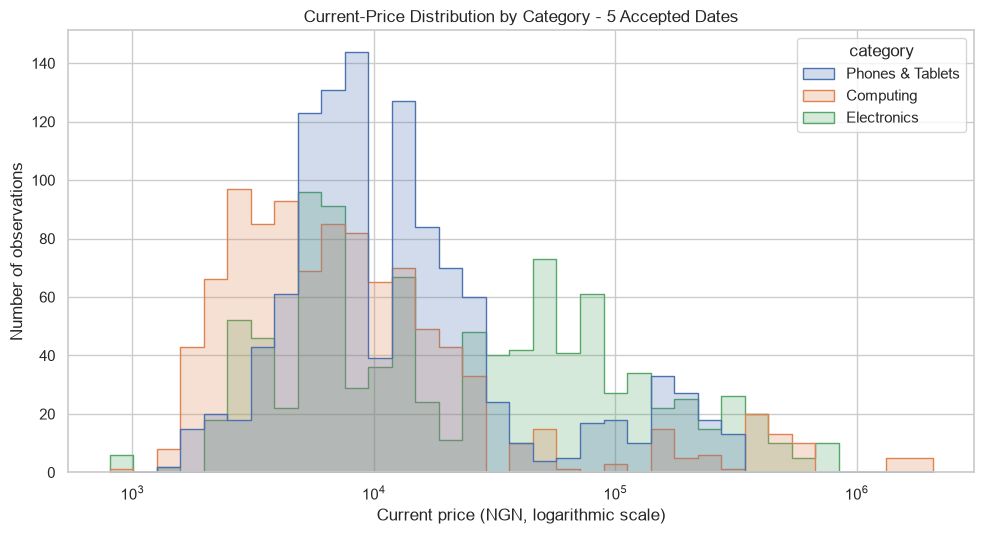

In [7]:
plt.figure(figsize=(10, 5.5))
sns.histplot(
    data=df,
    x="current_price",
    hue="category",
    bins=35,
    element="step",
    stat="count",
    common_norm=False,
    log_scale=(True, False),
)
plt.title(f"Current-Price Distribution by Category - {run_label}")
plt.xlabel("Current price (NGN, logarithmic scale)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

The five-day price distributions are strongly right-skewed, so the logarithmic price axis keeps both low-cost accessories and expensive devices visible. Median observed prices are NGN 6,480 for Computing, NGN 9,500 for Phones & Tablets and NGN 21,800 for Electronics. A small number of expensive products stretch the upper tails, so the median is more representative than the mean for a typical listing.

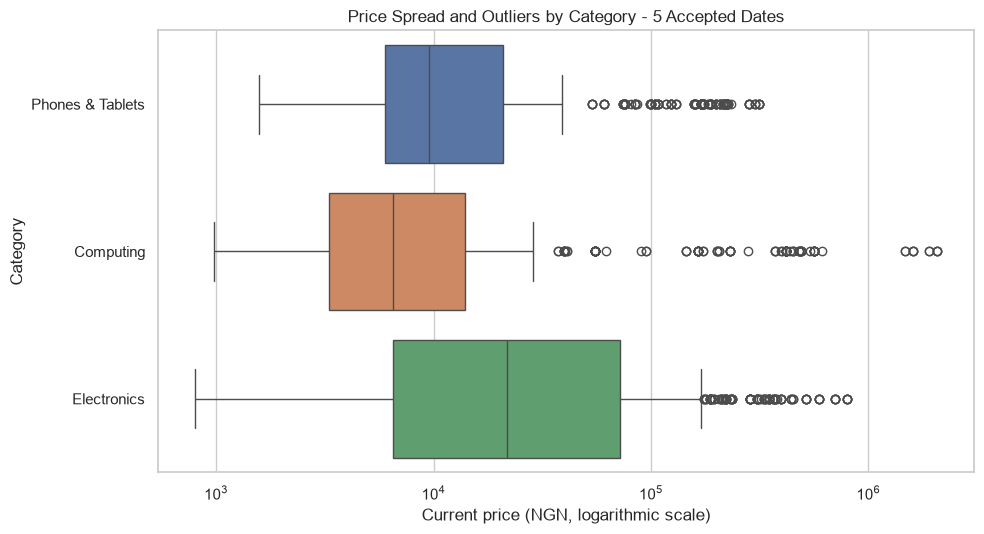

In [8]:
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, x="current_price", y="category", hue="category", legend=False)
plt.xscale("log")
plt.title(f"Price Spread and Outliers by Category - {run_label}")
plt.xlabel("Current price (NGN, logarithmic scale)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Using the standard 1.5-IQR rule, the five accepted dates contain 109 high-price outliers in Computing, 111 in Electronics and 145 in Phones & Tablets. Computing has the largest maximum price at NGN 2,066,198 even though its median is the lowest, showing how strongly expensive computers affect its mean. These are statistical outliers, not automatically data errors, because they remain positive and come from valid listings.

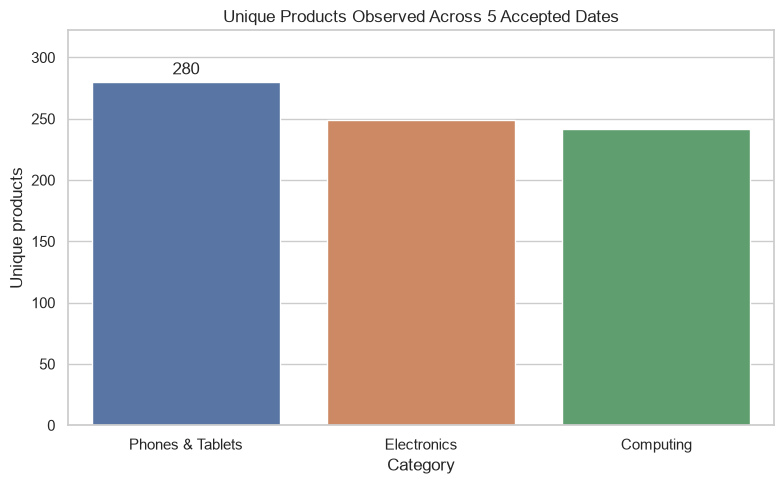

In [9]:
latest_products = (
    df.sort_values("scraped_at")
      .drop_duplicates("source_product_id", keep="last")
)
unique_category_counts = latest_products["category"].value_counts().rename("products")
count_frame = unique_category_counts.rename_axis("category").reset_index()
plt.figure(figsize=(8, 5))
axis = sns.barplot(data=count_frame, x="category", y="products", hue="category", legend=False)
axis.bar_label(axis.containers[0], padding=3)
plt.title(f"Unique Products Observed Across {run_label}")
plt.xlabel("Category")
plt.ylabel("Unique products")
plt.ylim(0, count_frame["products"].max() * 1.15)
plt.tight_layout()
plt.show()

Across the five accepted dates, 771 unique products were observed: 280 in Phones & Tablets, 249 in Electronics and 242 in Computing using each product's latest observation. Day 5 shares 620 products with earlier accepted dates, adds 15 products not seen earlier, and does not contain 136 products seen on an earlier accepted date. Absence from one daily sample does not prove that a product left the whole website.

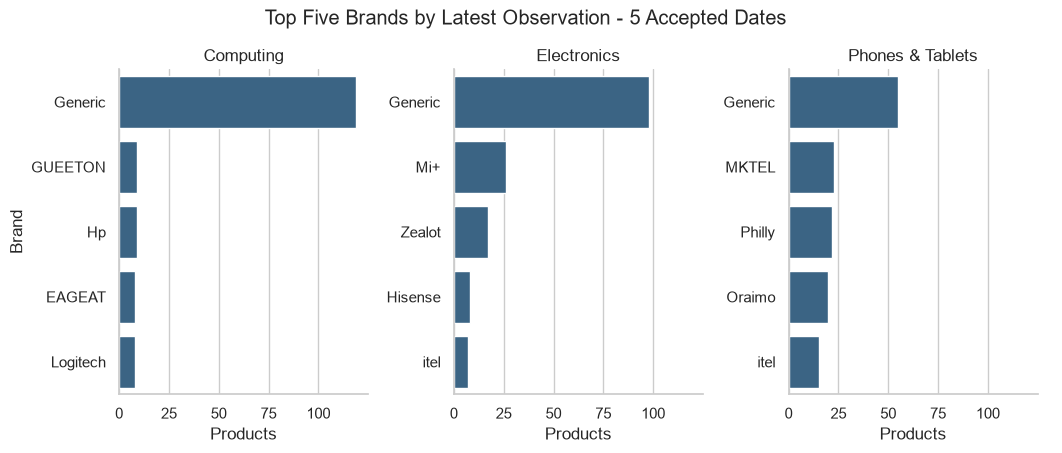

In [10]:
brand_counts = (
    latest_products.groupby(["category", "brand"], dropna=False)
      .size()
      .rename("products")
      .reset_index()
      .sort_values(["category", "products"], ascending=[True, False])
      .groupby("category", group_keys=False)
      .head(5)
)

grid = sns.catplot(
    data=brand_counts,
    x="products",
    y="brand",
    col="category",
    kind="bar",
    sharey=False,
    height=4.3,
    aspect=0.82,
    color="#2F6690",
)
grid.set_axis_labels("Products", "Brand")
grid.set_titles("{col_name}")
grid.figure.suptitle(f"Top Five Brands by Latest Observation - {run_label}", y=1.05)
plt.show()

The label `Generic` is the most frequent brand in every category: 119 Computing products, 98 Electronics products and 55 Phones & Tablets products. The next visible leaders include GUEETON, EAGEAT and Hp in Computing, Mi+ and Zealot in Electronics, and MKTEL, Philly and Oraimo in Phones & Tablets. Brand dominance here measures listing frequency in the five-day sample, not sales or market share.

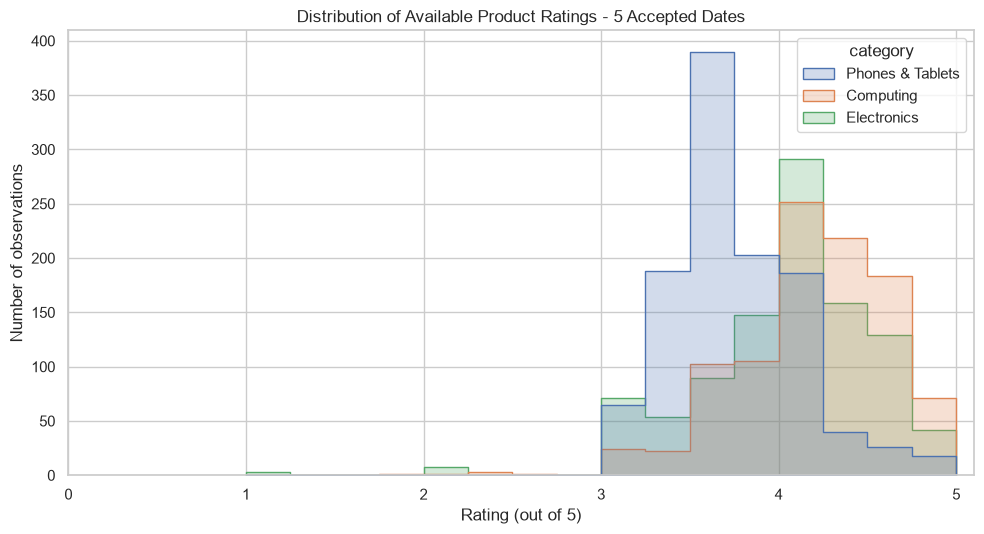

In [11]:
rating_data = df.dropna(subset=["rating"])
plt.figure(figsize=(10, 5.5))
sns.histplot(
    data=rating_data,
    x="rating",
    hue="category",
    binwidth=0.25,
    multiple="layer",
    element="step",
    common_norm=False,
)
plt.title(f"Distribution of Available Product Ratings - {run_label}")
plt.xlabel("Rating (out of 5)")
plt.ylabel("Number of observations")
plt.xlim(0, 5.1)
plt.tight_layout()
plt.show()

Ratings are available for 3,094 of 3,113 observations. Mean ratings are 4.17 for Computing, 4.01 for Electronics and 3.73 for Phones & Tablets, but these are observation-level summaries and do not control for review-count differences. The 19 missing ratings remain excluded rather than being treated as zero.

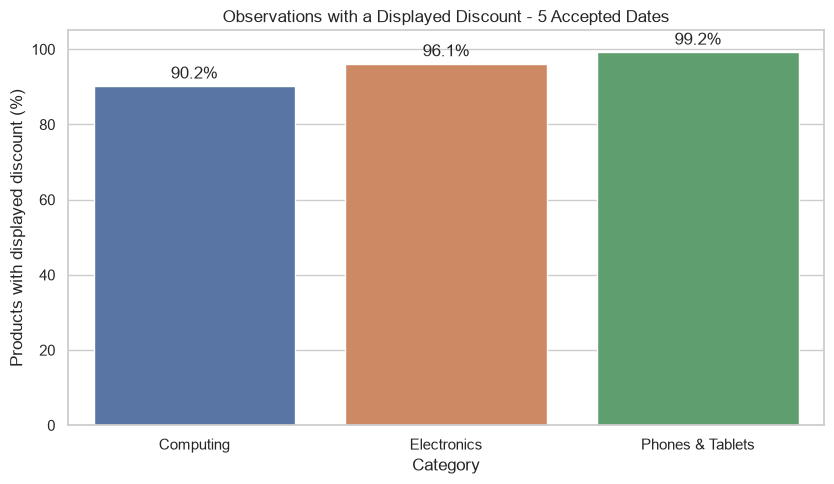

In [12]:
discount_summary = (
    df.groupby("category")
      .agg(
          total_products=("source_product_id", "size"),
          discounted_products=("displayed_discount_percentage", lambda values: values.notna().sum()),
      )
      .reset_index()
)
discount_summary["discounted_percentage"] = (
    discount_summary["discounted_products"] / discount_summary["total_products"] * 100
)

plt.figure(figsize=(8.5, 5))
axis = sns.barplot(
    data=discount_summary,
    x="category",
    y="discounted_percentage",
    hue="category",
    legend=False,
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title(f"Observations with a Displayed Discount - {run_label}")
plt.xlabel("Category")
plt.ylabel("Products with displayed discount (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

Displayed discounts are very common across the five accepted dates: 99.2% of Phones & Tablets observations, 96.1% of Electronics observations and 90.2% of Computing observations show one. The remaining 146 observations are not assumed to have a zero-percent discount; their displayed-discount field is missing because no old-price/discount pair was shown. This chart describes availability of discount evidence, not whether a discount guarantees good value.

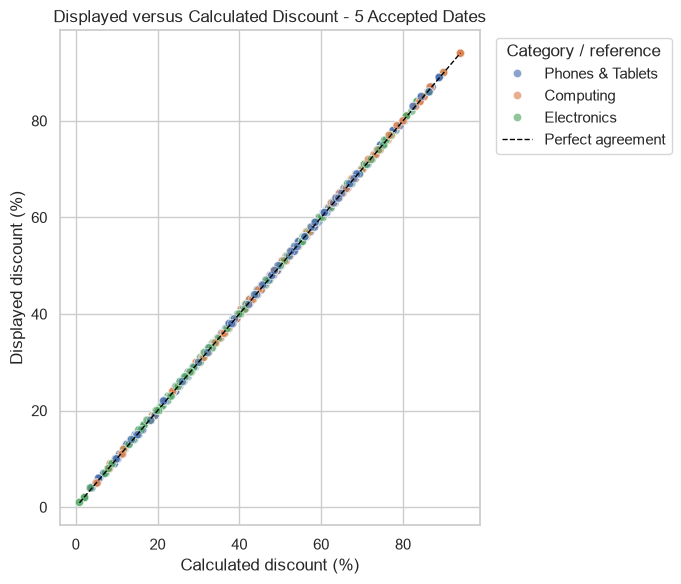

In [13]:
discount_pairs = df.dropna(
    subset=["displayed_discount_percentage", "calculated_discount_percentage"]
).copy()
discount_pairs["absolute_difference"] = (
    discount_pairs["displayed_discount_percentage"]
    - discount_pairs["calculated_discount_percentage"]
).abs()

plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=discount_pairs,
    x="calculated_discount_percentage",
    y="displayed_discount_percentage",
    hue="category",
    alpha=0.65,
    s=35,
)
lower = min(discount_pairs["calculated_discount_percentage"].min(), discount_pairs["displayed_discount_percentage"].min())
upper = max(discount_pairs["calculated_discount_percentage"].max(), discount_pairs["displayed_discount_percentage"].max())
plt.plot([lower, upper], [lower, upper], "--", color="black", linewidth=1, label="Perfect agreement")
plt.title(f"Displayed versus Calculated Discount - {run_label}")
plt.xlabel("Calculated discount (%)")
plt.ylabel("Displayed discount (%)")
plt.legend(title="Category / reference", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

There are 2,967 observations with both displayed and calculated discounts. Their mean absolute difference is 0.236 percentage points and the maximum is 0.55 points; none exceeds the documented two-percentage-point tolerance. The small gaps are consistent with Jumia displaying rounded whole-number percentages while the calculation uses exact listed prices.

,count
Observations on 2026-10-13,639
Observations on 2026-10-14,600
Observations on 2026-10-15,639
Observations on 2026-10-16,600
Observations on 2026-10-17,635
Unique products across available days,771
Products observed on all available days,491
Latest-day products shared with previous days,620
Products new in the latest-day sample,15
Previous products absent from latest-day sample,136


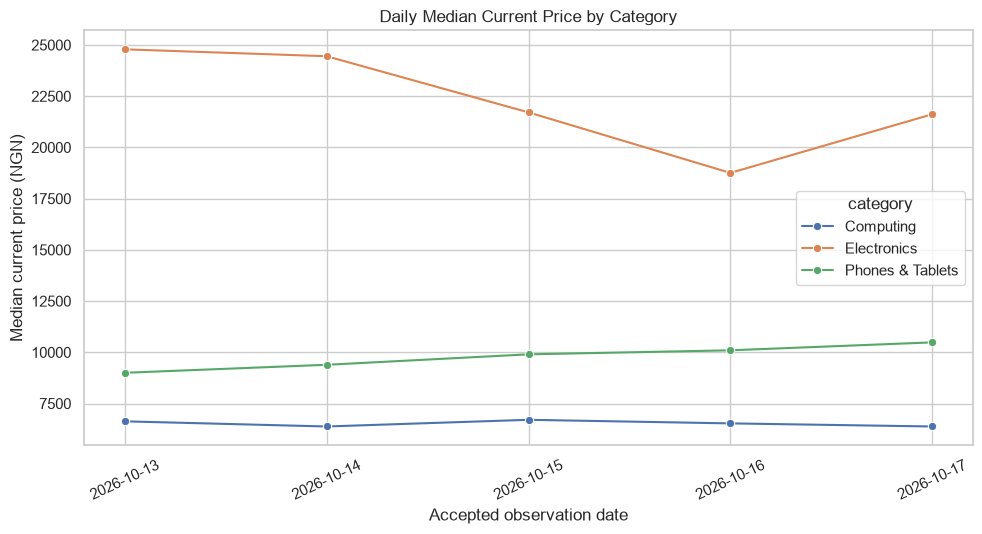

In [14]:
latest_date = available_dates[-1]
latest_day = df[df["scrape_date"] == latest_date].copy()
previous_latest = (
    df[df["scrape_date"] < latest_date]
      .sort_values("scraped_at")
      .drop_duplicates("source_product_id", keep="last")
)
latest_comparison = previous_latest.merge(
    latest_day,
    on="source_product_id",
    how="inner",
    suffixes=("_previous", "_latest"),
)

both_discounts = (
    latest_comparison["displayed_discount_percentage_previous"].notna()
    & latest_comparison["displayed_discount_percentage_latest"].notna()
)
comparison_counts = {
    f"Observations on {date}": int((df["scrape_date"] == date).sum())
    for date in available_dates
}
comparison_counts.update({
    "Unique products across available days": df["source_product_id"].nunique(),
    "Products observed on all available days": int(
        (df.groupby("source_product_id")["scrape_date"].nunique() == len(available_dates)).sum()
    ),
    "Latest-day products shared with previous days": len(latest_comparison),
    "Products new in the latest-day sample": latest_day.loc[
        ~latest_day["source_product_id"].isin(previous_latest["source_product_id"]),
        "source_product_id",
    ].nunique(),
    "Previous products absent from latest-day sample": previous_latest.loc[
        ~previous_latest["source_product_id"].isin(latest_day["source_product_id"]),
        "source_product_id",
    ].nunique(),
    "Overlapping products with a price change": int(
        latest_comparison["current_price_previous"].ne(latest_comparison["current_price_latest"]).sum()
    ),
    "Price increases from latest prior observation": int((
        latest_comparison["current_price_latest"] > latest_comparison["current_price_previous"]
    ).sum()),
    "Price decreases from latest prior observation": int((
        latest_comparison["current_price_latest"] < latest_comparison["current_price_previous"]
    ).sum()),
    "Comparable products with a displayed-discount change": int(
        latest_comparison.loc[both_discounts, "displayed_discount_percentage_previous"].ne(
            latest_comparison.loc[both_discounts, "displayed_discount_percentage_latest"]
        ).sum()
    ),
    "Displayed-discount increases": int((
        latest_comparison.loc[both_discounts, "displayed_discount_percentage_latest"]
        > latest_comparison.loc[both_discounts, "displayed_discount_percentage_previous"]
    ).sum()),
    "Displayed-discount decreases": int((
        latest_comparison.loc[both_discounts, "displayed_discount_percentage_latest"]
        < latest_comparison.loc[both_discounts, "displayed_discount_percentage_previous"]
    ).sum()),
    "Displayed discount became available": int((
        latest_comparison["displayed_discount_percentage_previous"].isna()
        & latest_comparison["displayed_discount_percentage_latest"].notna()
    ).sum()),
    "Displayed discount was no longer available": int((
        latest_comparison["displayed_discount_percentage_previous"].notna()
        & latest_comparison["displayed_discount_percentage_latest"].isna()
    ).sum()),
})
preliminary_comparison = pd.Series(comparison_counts)
display(preliminary_comparison.rename("count").to_frame())

daily_median_prices = (
    df.groupby(["scrape_date", "category"], as_index=False)["current_price"].median()
)
plt.figure(figsize=(10, 5.5))
sns.lineplot(
    data=daily_median_prices,
    x="scrape_date",
    y="current_price",
    hue="category",
    marker="o",
)
plt.title("Daily Median Current Price by Category")
plt.xlabel("Accepted observation date")
plt.ylabel("Median current price (NGN)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## G. Seven-day analysis placeholders

> Accepted Daily Runs 1-5 are currently available. Two planned dates remain, so seven-day trend conclusions cannot yet be made.

The preliminary Day 5 comparison contains 620 products also seen previously. Compared with each product's latest prior observation, 19 changed current price: 13 increased and 6 decreased. Among 592 products with displayed discounts in both observations, 16 changed displayed-discount percentage: 3 increased and 13 decreased. These are five-day sample checks only, not final trend results.

### Daily price changes

Day 5 is compared with the latest prior observation for the same stable product ID. The daily median-price chart uses the five genuine consecutive dates without filling absent product observations. Final daily-change analysis remains pending the remaining genuine runs.

### Daily discount changes

The preliminary comparison shows 16 numeric displayed-discount changes among 592 comparable products. Displayed-discount evidence became available for 1 overlapping product and was lost for none. Final discount trends remain pending the remaining genuine runs.

### Products with the largest movements

Five-day movements can now be calculated, but a final ranking will wait for all seven dates. Products will be ranked only when they have comparable genuine observations.

### Products appearing and disappearing

Day 5 contains 15 products not observed on Days 1-4, while 136 previously observed products are absent from the Day 5 sample. This describes presence in the collected category pages, not proof that products joined or left the whole website.

### Final relationship analysis

The final notebook will examine price-rating and review-count relationships after all seven days are combined. Review count will be treated as a limited popularity indicator, not direct sales evidence.

### Original Group 2 research question

**Which brands provide the best balance of lower prices, strong ratings and high review counts?** A scoring method and minimum sample-size rule will be defined after the full period is available; no final brand ranking is claimed from only five accepted dates.

## H. Reproducibility

- Expected cleaned inputs: accepted daily files under `data/cleaned/`
- Expected SQLite database: `database/jumia_ng.sqlite` containing all accepted dates (opened with `mode=ro`)
- Run from the repository root with **Restart Kernel and Run All**, or execute with `jupyter nbconvert --execute --to notebook --inplace notebooks/jumia_analysis.ipynb`.
- Required packages: Python 3, pandas, NumPy, Matplotlib, Seaborn, Jupyter/nbclient and the standard-library `sqlite3` module.
- The notebook reads the database only. Accepted raw CSV files must remain unchanged and must be protected by their manifest checksums.
- Re-run the notebook after each accepted daily file is cleaned and loaded; replace placeholders only with results calculated from genuine observations.